# M6.4 · 报警与人工接管

> 系统异常需要分级报警并路由到对应责任人；当自动策略无法安全处理时，切换到人工接管，
> 全程审计留痕，处理完再交还自动运行。

## 一、机制

1. **分级报警**：INFO/WARN/CRITICAL，按级别路由（日志/即时消息/电话），记录可统计；
2. **人工接管状态机**：AUTO → REQUESTED → TAKEOVER（暂停自动下单）→ RETURN；
3. **权限与审计**：接管需授权，未授权拒绝，所有操作留痕可追溯。

## 二、报警与接管

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import alert_handoff as ah
am = ah.AlertManager()
am.raise_alert('INFO', '系统启动'); am.raise_alert('WARN', '现金偏低')
am.raise_alert('CRITICAL', '触发熔断')
print('报警数 INFO=%d WARN=%d CRITICAL=%d' % (am.count('INFO'), am.count('WARN'), am.count('CRITICAL')))
for r in am.records: print(r)
ho = ah.HumanHandoff()
print('请求=%s 未授权=%s 授权=%s 阻断自动交易=%s 交还=%s'
      % (ho.request('熔断'), ho.take_over('张三', False), ho.take_over('张三', True),
         ho.auto_trading_blocked(), ho.return_to_auto('张三')))
print('审计条数=%d' % len(ho.audit))

报警数 INFO=1 WARN=1 CRITICAL=1
{'level': 'INFO', 'msg': '系统启动', 'channel': 'log'}
{'level': 'WARN', 'msg': '现金偏低', 'channel': 'im'}
{'level': 'CRITICAL', 'msg': '触发熔断', 'channel': 'phone+im'}
请求=REQUESTED 未授权=DENIED 授权=TAKEOVER 阻断自动交易=True 交还=AUTO
审计条数=4


## 三、可视化

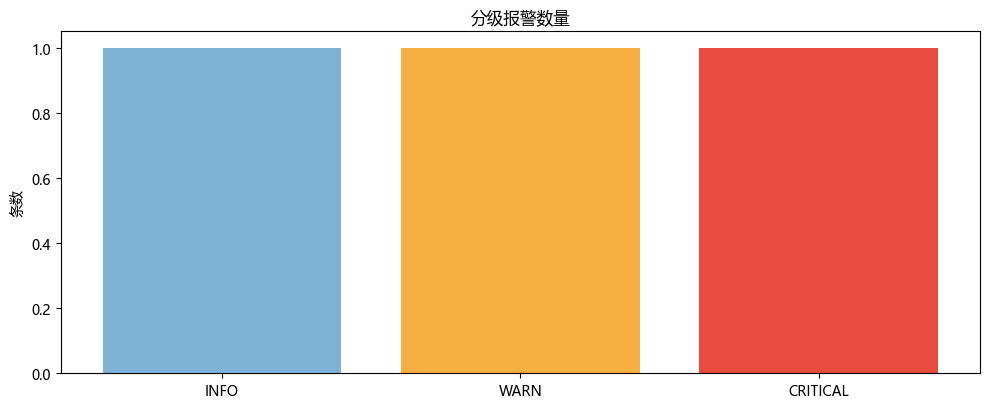

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 4.2))
levels = ['INFO', 'WARN', 'CRITICAL']
ax.bar(levels, [am.count(l) for l in levels],
       color=['#7fb3d5', '#f5b041', '#e74c3c'])
ax.set_title('分级报警数量'); ax.set_ylabel('条数')
plt.tight_layout(); plt.show()

## 四、面试要点

- **报警为何要分级？** 不同严重度走不同通知渠道，避免报警风暴，确保关键事件（CRITICAL）能电话直达责任人。
- **人工接管后系统如何变化？** 暂停自动下单，交易员在受控权限内操作，策略只观察不发单。
- **为什么要审计留痕？** 记录接管请求、授权、操作与交还，便于事后追责与复盘，满足合规。
- **接管交还需要确认什么？** 系统状态正常、持仓与账目核对一致后，才恢复自动运行。

## 五、练习

1. 实现报警去重与聚合（同类报警合并）。
2. 增加升级机制（WARN 未处理自动升级）。
3. 给接管操作加操作权限分级。
4. 设计接管期间的双人复核流程。